<a href="https://colab.research.google.com/github/romanotancredi/equity-investment-research-portfolio/blob/main/06_investment_review_and_recommendations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Phase 6 — Investment Review & Portfolio Recommendations

## Investment Objective

Evaluate the historical performance, risk characteristics
and regional positioning of a hypothetical global equity
portfolio relative to the Vanguard Total World Stock ETF (VT).

The analysis aims to identify key sources of relative
performance, evaluate portfolio risks and formulate
evidence-based investment recommendations.

### Portfolio Construction
- US equities (VTI): 60%
- Developed ex-US equities (VEA): 30%
- Emerging markets equities (VWO): 10%
- Benchmark: Vanguard Total World Stock ETF (VT)
- Rebalancing assumption: Daily


In [1]:

# ---------------------------------------------------------
# PHASE 6 - STEP 1: LOAD AND RECONSTRUCT PORTFOLIO RETURNS
# ---------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the same adjusted ETF prices used in previous phases.
url = (
    "https://raw.githubusercontent.com/romanotancredi/"
    "equity-investment-research-portfolio/refs/heads/main/"
    "01-equity-performance-and-risk/data/etf_prices.csv"
)

prices = pd.read_csv(
    url,
    index_col="Date",
    parse_dates=["Date"]
).sort_index()

# Calculate daily ETF returns.
daily_returns = prices.pct_change().dropna()

# Define the portfolio's constant target weights.
weights = pd.Series({
    "VTI": 0.60,
    "VEA": 0.30,
    "VWO": 0.10
})

# Reconstruct daily portfolio returns.
# This assumes daily rebalancing to target weights.
portfolio_returns = daily_returns[weights.index].dot(weights)

# Extract daily benchmark returns.
benchmark_returns = daily_returns["VT"]

# Combine both into one DataFrame.
performance = pd.DataFrame({
    "Portfolio": portfolio_returns,
    "Benchmark": benchmark_returns
})

# Calculate cumulative growth from a starting value of 100.
cumulative_performance = (1 + performance).cumprod() * 100

# Display the latest values.
display(cumulative_performance.tail())

,Portfolio,Benchmark
Date,,
2026-10-26,221.561105,218.158606
2026-10-27,223.042495,219.620986
2026-10-28,224.000169,220.456616
2026-10-29,223.629720,220.010951
2026-10-30,219.852348,216.334121


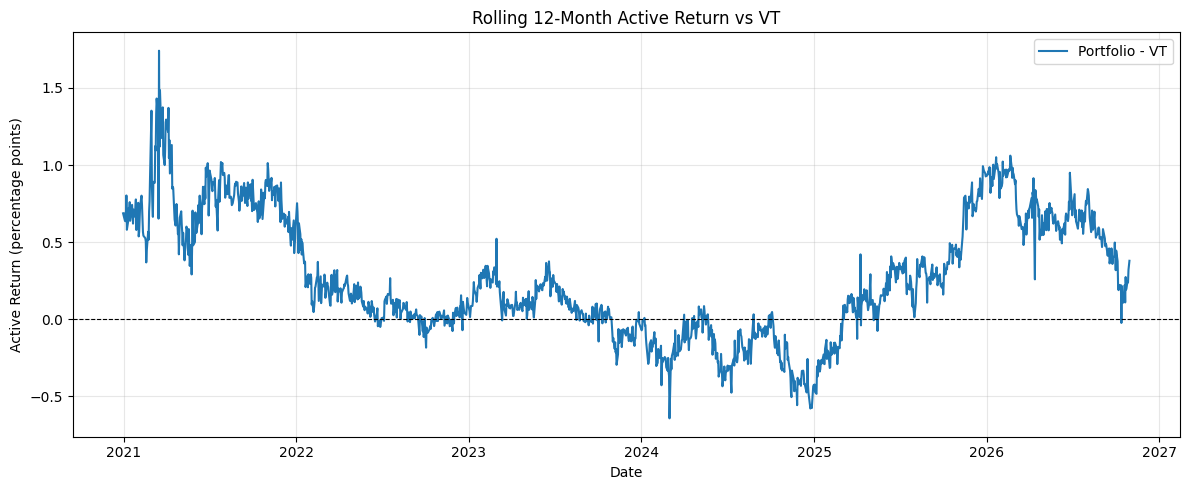

Positive rolling 12-month periods: 74.3%


In [2]:

# ---------------------------------------------------------
# PHASE 6 - STEP 2: ROLLING 12-MONTH RELATIVE PERFORMANCE
# ---------------------------------------------------------

# Define a standard 252-trading-day window.
window = 252

# Calculate compounded rolling 12-month returns.
rolling_returns = (
    (1 + performance)
    .rolling(window)
    .apply(np.prod, raw=True)
    - 1
)

# Calculate the rolling return difference.
# This is expressed in percentage points, not as
# a compounded portfolio/benchmark return ratio.
rolling_active_return = (
    rolling_returns["Portfolio"]
    - rolling_returns["Benchmark"]
) * 100

# Create the chart.
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    rolling_active_return.index,
    rolling_active_return,
    label="Portfolio - VT"
)

ax.axhline(0, color="black", linestyle="--", linewidth=0.8)

ax.set_title("Rolling 12-Month Active Return vs VT")
ax.set_xlabel("Date")
ax.set_ylabel("Active Return (percentage points)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Assess the consistency of outperformance.
valid_periods = rolling_active_return.dropna()

outperformance_frequency = (
    (valid_periods > 0).mean() * 100
)

print(
    f"Positive rolling 12-month periods: "
    f"{outperformance_frequency:.1f}%"
)